## What this demonstration shows, in plain language

Milestone 1 built one graph per patient:

- the **patient**
- their **tumour sample**
- the **genes** that are mutated, highly amplified, or homozygously deleted in that tumour

The clinical question is the same one as before: **did that patient's cancer progress within 36 months?** A record that ends before 36 months with no progression is left out of the set rather than called a "no". Follow-up time makes that yes/no label and is never given to the model as an input.

36 months is the endpoint used everywhere in this notebook: it keeps 498 patients, 89 of whom had progressed by then.

### What a hop is

Every altered gene is also tied into **PrimeKG**, a public map of proteins, pathways, drugs, and diseases. A hop is one step along that map, counted away from the patient's own observed alterations.

| Depth | What sits at that depth | Where it comes from |
| --- | --- | --- |
| hop 0 | patient -> sample -> altered gene | measured in this patient |
| hop 1 | protein partners inside our 500-gene panel, plus pathways, drugs, and breast/mammary disease nodes of the altered genes | one PrimeKG step |
| hop 2 | panel genes that share a pathway with an altered gene, for example ERBB2 and PIK3CA through one PI3K pathway | two PrimeKG steps |
| hop 3 | pathways, drugs, and diseases of those hop-2 genes | three PrimeKG steps |

### Why hops help the GNN at all

A GNN does one thing: it passes a message along each edge and mixes the messages it receives. Edges are therefore the model's only way to move information between genes. PrimeKG steps add three useful things:

- **Context for an alteration the patient was never tested for.** A tumour report may show an ERBB2 amplification and say nothing about PIK3CA. Through one shared pathway node, the model can still see that this tumour sits in PI3K signalling.
- **A road from one gene to another.** Without the pathway node in the middle, the two genes are unconnected and no message can travel between them.
- **Sharing between patients.** Two patients whose altered genes sit in the same pathway end up with similar representations. With 498 patients and 89 events, that sharing is worth more than one extra feature per patient.

Deeper is not automatically better, though. Every extra step drags in more nodes and edges, and all of them compete for the same three message-passing layers, so the patient-specific signal gets diluted.

PrimeKG depth and network depth are separate numbers. The hop count decides **which biomedical nodes exist** in the patient's graph. All three graph models always run three message-passing layers. "Deeper graph" never means "deeper neural network".

### What GSL does

Instead of picking one PrimeKG depth for the whole cohort (K = 2 for everyone, or K = 3 for everyone), GSL keeps the depth that already worked and makes the extra ring optional, patient by patient. Every PrimeKG edge the graph stores gets a weight, and that weight multiplies the message passed along it:

| Part of the graph | Learned weight | Why |
| --- | --- | --- |
| patient -> sample -> altered gene | always 1 | Observed in the patient, so it is never re-weighted. |
| PrimeKG hops 1 and 2 | not gated, start at exactly 1 | The pathway, drug, and disease neighbours the fixed 2-hop model was already using. |
| PrimeKG hop 3 | per-patient gate, off until it opens past 0.5 | The only depth the model may change. |

Three graph models read this weighted graph: **GCN**, **GraphSAGE**, and **GATv2**. The table model that ignores the graph is not part of this demonstration.

The rest of the notebook answers four questions: what changed in GSL and why the score moved, how the new numbers compare with the fixed 2-hop graph, what the learned weights did depth by depth, and which stored paths pushed the score in the explained patients. It then closes with two figures: one patient's graph fused with PrimeKG, and the single highest-scoring stored path read step by step.


## What changed in GSL, and why the score improved

The first GSL run made the fused models *worse* than the fixed 2-hop graph: GCN AUPRC fell from 0.396 to 0.316, and the best of the three (GraphSAGE) only reached 0.383. Four changes fixed that. Each one closes off a way for the scorer to throw away signal the fixed graph already had.

**1. The depth that already worked is not gated.** The fixed 2-hop graph is the neighbourhood that already worked, so the scorer cannot switch a whole ring of it off: the patient gate applies to hop 3 and beyond only, and a hop-1 or hop-2 edge starts at exactly 1 and can then be moved only by its own per-edge residual. The first scorer was a free sigmoid over `[source, destination, relation, patient, hop]`. It started near 0.5 and then drove every 2-hop edge below 0.5 — exactly the pathway and drug edges the stronger GCN was using. Hop is no longer an input to the scorer's edge MLP, so the scorer cannot switch a whole ring off.

**2. Hop 3 is gated per patient and starts closed.** The hop bias is `-2` for hop 3, so its gate is `sigmoid(-2) ≈ 0.12`, and hop-3 messages are hard off until that patient's gate crosses 0.5. Hops 1 and 2 start open. The run therefore begins at the fixed 2-hop graph and can only move away from it patient by patient. This is the depth search, done per patient instead of as one K for everyone.

**3. The edge residual has a slope at weight 1.** `2 * sigmoid((delta + relation_logit) / temperature)` is exactly 1 at the zero start, and unlike `clamp(weight, max=1)` its gradient there is not zero. In the first attempt the weights sat at 1 with no way to learn. `gsl_temperature: 4` keeps the residual moving slowly, the structure parameters use `gsl_learning_rate` with no weight decay, and the straight-through gate keeps its slope while it is closed.

**4. The graph correction is anchored to a frozen clinical score.** Age, sex, subtype, stage, and M stage are turned into one frozen clinical score on the training part of each split. The graph term starts at zero, the mix starts small, and the untouched clinical score is kept whenever no later epoch improves validation AUPRC. So the graph can only add a correction to that score; it cannot drag a patient below what the clinical fields already say.


## The result: GSL with the hop prior against the fixed 2-hop graph

498 patients have a known 36-month window and 89 of them progressed by then. Every run in these tables uses the same stratified 5-fold split, so the columns are directly comparable. AUROC 0.50 is a coin flip, and the AUPRC of a coin flip here is 0.179, because only 18% of patients progressed by 36 months.

AUPRC, the metric that matters most on this class balance:

| Model | Fixed 2-hop graph | First GSL, free weights | **GSL + hop prior** |
| --- | --- | --- | --- |
| GCN | 0.396 ± 0.091 | 0.316 ± 0.111 | **0.456 ± 0.129** |
| GraphSAGE | 0.379 ± 0.091 | 0.383 ± 0.103 | **0.463 ± 0.133** |
| GATv2 | 0.355 ± 0.060 | 0.366 ± 0.091 | **0.463 ± 0.133** |

AUROC on the same folds:

| Model | Fixed 2-hop graph | First GSL, free weights | **GSL + hop prior** |
| --- | --- | --- | --- |
| GCN | 0.680 ± 0.076 | 0.609 ± 0.080 | **0.701 ± 0.079** |
| GraphSAGE | 0.650 ± 0.045 | 0.660 ± 0.116 | **0.703 ± 0.080** |
| GATv2 | 0.631 ± 0.046 | 0.627 ± 0.062 | **0.7029 ± 0.0810** |

One cell in that table is carried to four decimals. The hop-prior GATv2 AUROC is 0.7029 ± 0.0810 and the frozen clinical score's own row is 0.7030 ± 0.0807, so at three decimals the two would print identically. They are not the same measurement, so that cell stays unrounded instead of looking like a copy of the anchor.

Read against the fixed 2-hop graph, GSL with the hop prior adds **+0.060, +0.084, and +0.108 AUPRC** for GCN, GraphSAGE, and GATv2, and **+0.02, +0.05, +0.07 AUROC**. Against the first GSL attempt the gains are **+0.140, +0.080, and +0.097 AUPRC**. The worst-hit model of that first attempt, GCN, goes from 0.316 back to 0.456 — above the fixed 2-hop GCN it started from.

Two honest readings of the same table:

- The three graph models land in a band of 0.456–0.463 AUPRC and 0.701–0.703 AUROC, which is level with the frozen clinical score the graph correction is anchored to. The graph stage no longer costs accuracy, but it does not add a new signal either.
- With 89 events and a fold-to-fold spread of about ±0.13 AUPRC, a +0.06 AUPRC move is not a significance claim. What is clearly visible is the removal of the failure: GSL stopped destroying the layout the fixed graph had already found.

In the figures below, the first two panels are the 5-fold means with the fold spread (error bars) for the three graph models. The right panel is the weight each depth was given: the first GSL run from its own per-edge report, the hop-prior run at its 1.0 starting value for hops 0–2 and at its hop-3 gate value (that run's per-edge report was not kept, so those four bars are the design starting point, not a measurement), against the 0.5 line where a hop has to open.

The three runs behind these columns are `outputs/gnn_benchmark_36m` (fixed 2-hop), `outputs/gnn_benchmark_gsl` (first GSL), and `outputs/gnn_benchmark_gsl_prior` (hop prior). The first two columns are read from those run directories, which are in the repository; `outputs/gnn_benchmark_gsl_prior` is in no commit, so the hop-prior column comes from that run's own report and cannot be recomputed here. Regenerate the figure with `python scripts/plot_gsl_hop_prior.py`.


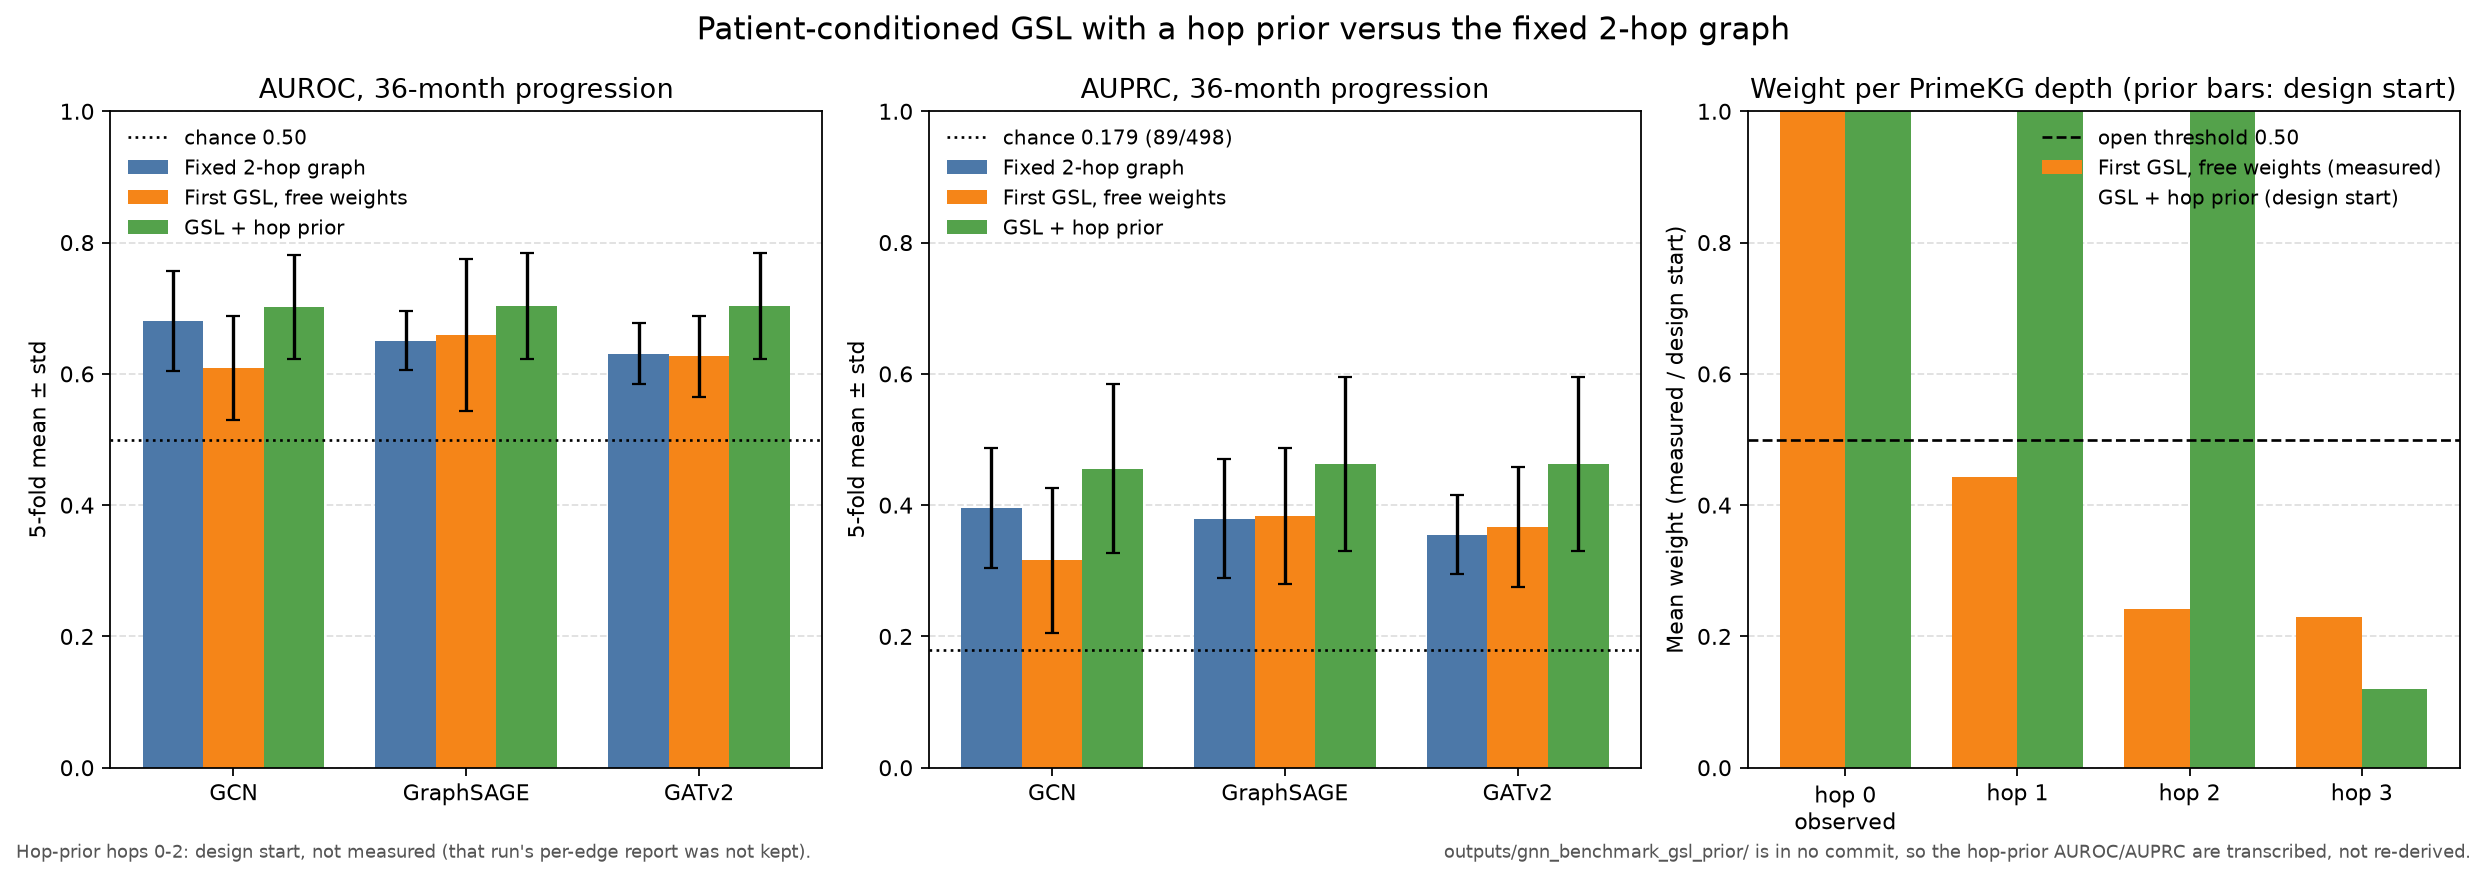

In [1]:
from IPython.display import Image, display
display(Image('outputs/gnn_benchmark_gsl/gsl_prior_comparison_bars.png'))


## What the learned weights did: the model chose K = 2

The hop-3 gate is where the depth decision is made, so that is the number to look at.

| Depth | Weight in this run | Result |
| --- | --- | --- |
| hop 0, observed | exactly 1 | Patient edges are facts, never re-weighted. |
| hop 1 and hop 2 | never gated, start at exactly 1 | The fixed 2-hop prior, kept intact: no ring-level switch, while each edge can still be re-weighted by its own residual. |
| hop 3 | gate `sigmoid(-2) ≈ 0.12`, opens past 0.5 | Never crossed 0.5 on any of the **1,764** hop-3 edges in the explained graphs. |

So the model's answer to "how many hops?" is **K = 2**: the same neighbourhood the fixed graph used. It was allowed to open a third ring for each patient and it left that ring off for every patient. A single global K search would have landed in the same place here; this version is allowed to decide per patient and still decides K = 2.

Why the third ring stayed shut:

- **It starts closed and has to earn its way open.** A hop-3 edge contributes nothing until that patient's gate crosses 0.5, and with `gsl_temperature: 4` the residual inside the prior moves slowly. Opening the ring would need a consistent validation-AUPRC gain across epochs, and none appeared.
- **Hop 3 mostly repeats hop 1 and hop 2.** A hop-3 node is reached *through* a hop-1 or hop-2 node, so its own pathway, drug, and disease neighbourhoods overlap the ones already stored. The first GSL run's per-edge report shows how lopsided that mix is: 7,187 pathway links, 2,225 drug links, 2,063 protein links, and 1,705 disease links, i.e. the same kinds of nodes at every depth rather than a new kind of evidence. Extra edges that carry the same message dilute the average instead of informing it.
- **The useful signal for this endpoint saturates at two hops.** The fixed 2-hop graph is the strongest graph layout found for this endpoint so far, and the gate is exactly the mechanism that would reveal a complementary third ring if there were one. It did not open.

### What the first GSL run did, for contrast

`outputs/gnn_benchmark_gsl/gsl_edges.csv` is the per-edge report of the first GSL run on the explained progression cases (GraphSAGE scorer, 13,832 stored forward edges over 8 patients).

| Depth | Edges | Mean weight | Median | Would pass 0.5 |
| --- | --- | --- | --- | --- |
| hop 0, observed | 652 | 1.000 | 1.000 | 100% |
| hop 1 | 5,341 | 0.442 | 0.527 | 52% |
| hop 2 | 5,745 | 0.242 | 0.255 | 0% |
| hop 3 | 2,094 | 0.229 | 0.219 | 19% |

The free scorer switched off the *whole* hop-2 ring — the pathway, drug, and disease neighbours the fixed 2-hop model depended on, none of them above 0.5 — and kept about a fifth of the deeper hop-3 ring instead. That is the opposite of the layout the fixed graph had. It is where the 0.396 to 0.316 AUPRC loss came from. An edge weight is not decoration: it decides which biology the GNN is allowed to see.


## Why hop 4 and beyond are not part of this work

- **Nothing is retrieved there.** The builder retrieves up to `max_candidate_hops: 3`, so the patient graphs contain no hop-4 edges at all. A weight exists only for edges the graph already stores, and there is no edge to weight. (The scorer keeps slots up to depth 8, so a future run could retrieve a deeper ring without a code change — once the cost below is justified.)
- **Cost grows with every step.** Each extra step multiplies the neighbourhood: in the first GSL run the stored edges already split into 5,341 at hop 1, 5,745 at hop 2, and 2,094 at hop 3. All of those nodes and edges go through the same three message-passing layers, and more of them means more averaging of the same patient signal.
- **The biology stops being about this tumour.** An altered gene -> pathway -> another gene is a statement about how those genes are wired. Two or three more steps is "some gene reaches some pathway reaches some disease", which is true of almost any pair of genes in a map of this size. At that distance an edge is not evidence, it is noise, and the model has no reason to trust it.
- **The experiment has already run.** The 3-hop candidate *is* the "one step further" test: it was offered to the model per patient, inside the fixed 2-hop prior, with the freedom to open it. The model declined. Spending retrieval, memory, and dilution budget on hop 4 is not what this result argues for.


## Symbolic path importance: which stored paths pushed a score

The tables above say how well the models rank. They do not say which stored biology moved a given patient's score. That second report exists, and the pipeline writes it on every run: `outputs/gnn_benchmark_gsl/explanations.csv` is the path report of the first GSL run, the same run as the middle column of the tables above.

Two different numbers are involved, and they are not the same thing:

1. **Patient probability.** The model's chance that this patient progressed by 36 months. The eight explained patients all sit between 0.90 and 0.96, because the report explains the highest-scoring true positives first.
2. **Edge importance.** A score between 0 and 1 for an edge that is *already stored* in that patient's graph. It is not the probability that the biology is true — the edge is either a PrimeKG fact or the patient's own alteration. It says how much the explanation method credited that edge in the prediction that was made.

`path_score` is the mean of the edge importances along one path, and every printed path is a walk over stored edges only: patient → sample → altered gene, then up to two more steps into PrimeKG. The report cannot state anything the graph does not contain.

Where the edge importances come from (`src/explain.py`): **GATv2 attention** when GATv2 is the model being explained, otherwise a **GNNExplainer** edge mask, and only if neither is available an altered-gene prior (1.0 on an altered gene's own edges, 0.2 elsewhere). The explained model in this run is GraphSAGE, so every row records the method as `gnnexplainer`.

Top-ranked path for four of the eight explained patients:

| Patient | Model risk | Path score | Path, stored edges only |
| --- | --- | --- | --- |
| TCGA-UU-A93S | 0.937 | 0.447 | patient → sample → **GATA3**, high-level amplification → disease *breast neoplasm* |
| TCGA-A2-A0SW | 0.958 | 0.436 | patient → sample → **PIK3R1**, mutation → pathway *Constitutive Signaling by EGFRvIII* |
| TCGA-AC-A2FE | 0.954 | 0.435 | patient → sample → **SHANK2**, high-level amplification → **PIK3R1** → pathway *PI-3K cascade: FGFR1* |
| TCGA-BH-A18J | 0.959 | 0.332 | patient → sample → **PIK3CA**, mutation → drug *Copanlisib* |

What that does and does not say:

- The chains are real stored edges rather than sentences we wrote, and they read like the disease: a mutated PIK3CA gene linked by PrimeKG to the PI3K inhibitor Copanlisib, PIK3R1 linked to an EGFRvIII signalling pathway, amplified GATA3 linked to a breast neoplasm node.
- They explain a prediction that was already made. They are not evidence that the graph carried the predictive signal — ranking is what AUPRC measures, and the ranking still comes mostly from the clinical fields.
- Every one of these paths stops at a hop-1 or hop-2 edge: the walk goes two steps past the altered gene and no further. That is the same two-hop ceiling the weight table showed, now seen from the path side.
- Within one patient the top three path scores are nearly identical (0.3317, 0.3307, and 0.3299 for TCGA-BH-A18J), so the order among them is not a claim about which pathway matters most.
- The report covers the explained subset — the highest-scoring true positives — not the whole cohort. It is a readable sample of what the model looked at, not a population-level importance ranking.

The cell below reads the same file, so those four rows can be checked against all eight patients line by line.


In [ ]:
import pandas as pd

paths = pd.read_csv('outputs/gnn_benchmark_gsl/explanations.csv')
top = paths[paths['path_rank'] == 1]
top[['patient_id', 'y_prob', 'path_score', 'score_source', 'path']].reset_index(drop=True)


## The patient graph, fused with PrimeKG

A patient's graph is two kinds of fact stitched together. The patient, the sample, and the altered genes are facts measured in this tumour. Everything past an altered gene is a PrimeKG record: partner proteins, pathways, drugs, diseases. Fused means both live in one directed graph with named relations on the edges, which is why a walk through it can be printed as a sentence instead of a score.

The figure below is one patient's neighbourhood, TCGA-AO-A0J5, drawn from the three stored walks the fixed 2-hop run writes for that patient (`outputs/gnn_benchmark_36m/explanations.csv`, the same file format as the GSL path report above). Those three walks are:

| Altered gene in this sample | PrimeKG part of the walk | Where the walk ends |
| --- | --- | --- |
| AKT3, high-level amplification | protein_protein → PIK3R1, then pathway_protein | pathway *Downstream signal transduction* |
| ACTN2, high-level amplification | pathway_protein | pathway *Nephrin family interactions* |
| AKT3, high-level amplification | protein_protein → AKT1, then disease_protein | disease *breast adenocarcinoma* |

Every node is a stored node and every arrow is a stored edge with its relation name printed, so the picture can be checked against the CSV line by line. The graph the model reads also holds that patient's other PrimeKG edges on the same genes; the figure keeps just these walks so the shape stays readable.

Two things to hold on to while reading it:

- `protein_protein` is a PrimeKG record that two proteins interact. It is not a link created because both genes happen to be altered in this sample: AKT3 and PIK3R1 are joined by the map, not by the tumour.
- An edge in the picture is a place the model could look, not a claim that it did. Which edges the explanation credited is what the next figure is about.


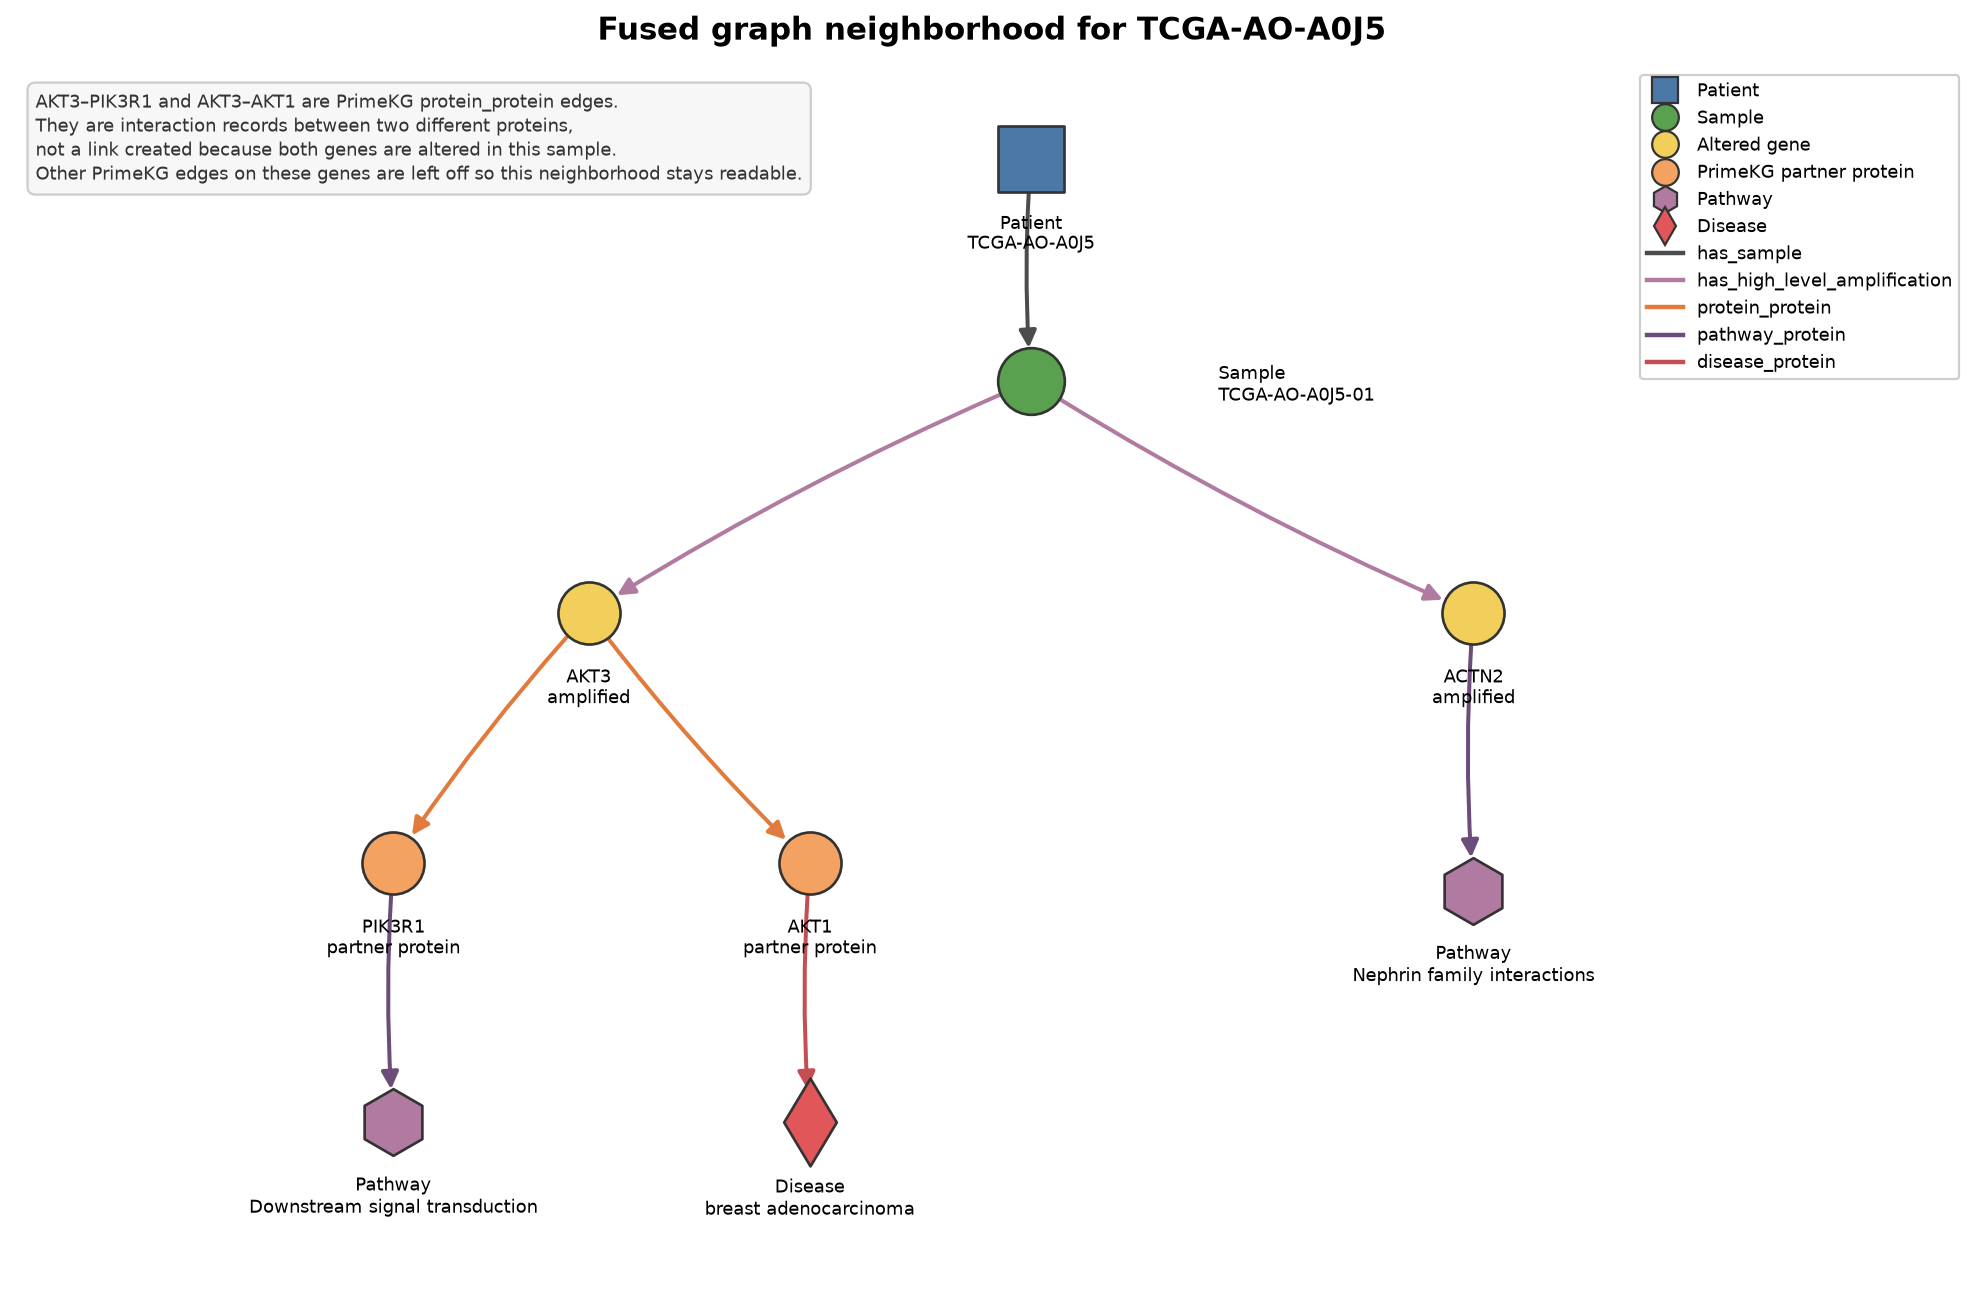

In [2]:
# Drawn by scripts/plot_fused_graph_example.py from the stored walks of this patient.
from IPython.display import Image, display

display(Image('outputs/gnn_benchmark_36m/fused_graph_example.png'))


## The path with the highest path score, read step by step

The report above ranks stored walks. Take the single highest-ranked row in the whole file and read it exactly as it is stored:

> patient:TCGA-UU-A93S -has_sample-> sample:TCGA-UU-A93S-01 -has_high_level_amplification-> gene:GATA3:2625 (GATA3) -disease_protein-> disease:21100 (breast neoplasm)

That row carries `path_score` 0.447, path rank 1 of that patient's three walks, and edge importances from `gnnexplainer`; the model's risk for the patient is 0.937. It is the same patient and the same score as the top line of the path table two cells above.

Read as a sentence: this patient's sample carries a high-level amplification of GATA3, and PrimeKG records a GATA3–breast neoplasm association. Every arrow is a relation the graph stores — `has_sample`, `has_high_level_amplification`, `disease_protein` — so the chain is symbolic in the literal sense: named relations over nodes, walkable, and checkable against the file. That is the difference from a bare importance number. A 0.447 on its own cannot be argued with; "GATA3 amplified in this sample, then a breast neoplasm disease node, in this patient's graph" can be looked up, questioned, and corrected.

The figure below draws that single row and adds nothing to it. The nodes, the arrow directions, and the relation names all come from the CSV, and the raw string is printed along the bottom of the figure so the drawing can be checked against the file.

Three things worth saying plainly about what the chain is and is not:

- It explains a prediction that was already made. The walk does not show that GATA3 or the disease node carried the signal; it shows what the edge importances credited in this patient.
- It has to be read next to the earlier tables. Ranking is what AUPRC measures, and the ranking there still comes mostly from the clinical fields, so a readable chain is not a new clinical finding.
- The report covers the eight highest-scoring true positives, and within one patient the top three path scores are nearly tied (0.447, 0.446, and 0.446 here). The order among them is not a claim about which pathway matters most.

One provenance check, because a path report is only useful if it is clean: neither the scorer nor the frozen clinical score reads `PFS_STATUS`, `PFS_MONTHS`, or any other outcome column, and the frozen clinical score is fit on the training part of each split, never on the held-out patients.


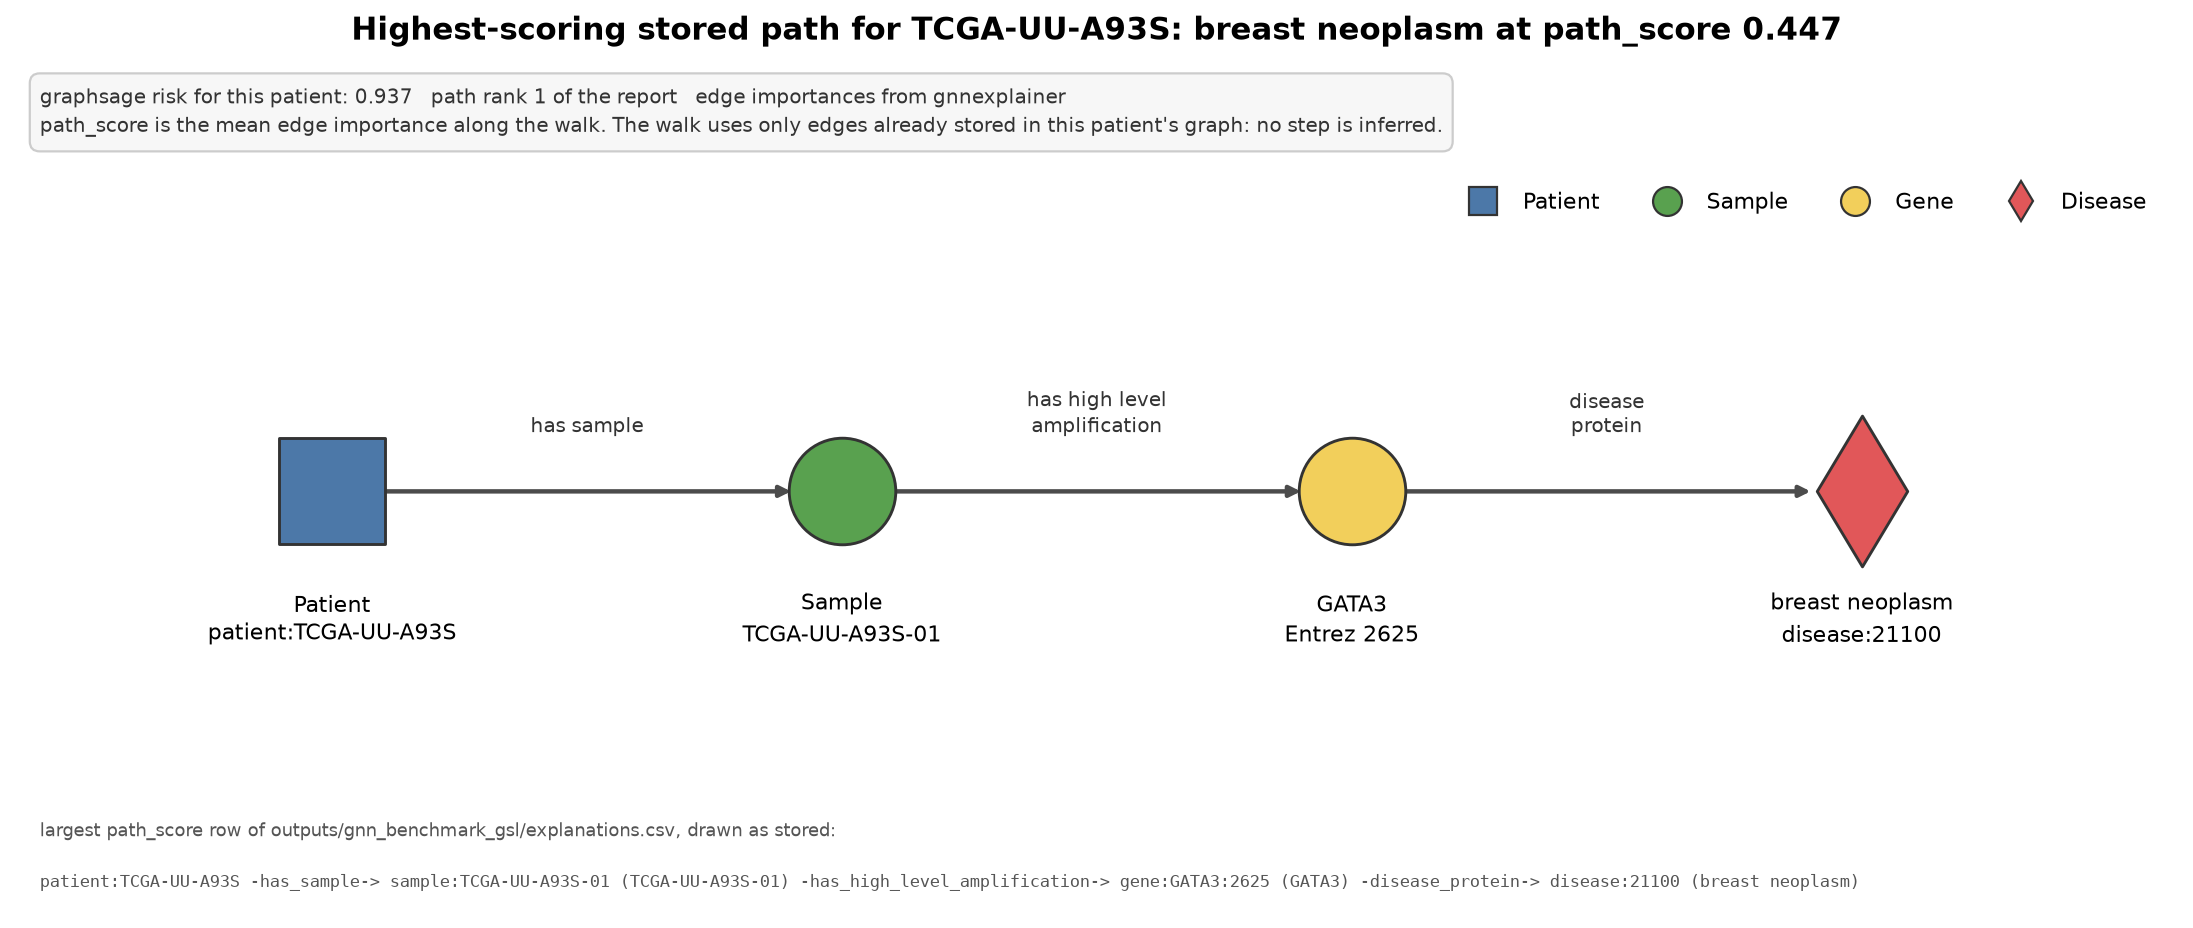

In [3]:
# Drawn by scripts/plot_top_path.py from the largest path_score row of the report below.
from IPython.display import Image, display

display(Image('outputs/gnn_benchmark_gsl/top_path_symbolic.png'))
